In [9]:
from brian2 import *
from brian2tools import *
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np
import imageio
import os
from scipy.signal import convolve2d

n_rc=14
pattern_duration = 1000*ms
num_patterns = 12
# kernel = np.array([
#     [0,  -1,  0],
#     [-1,  4, -1],
#     [0,  -1,  0]
# ], dtype=np.float32)
def create_mexican_hat_kernel():
    from scipy.ndimage import gaussian_filter
    center = np.zeros((3,3))
    center[1,1] = 1.0
    g1 = gaussian_filter(center, sigma=0.5)
    g2 = gaussian_filter(center, sigma=1.0)
    return g1 - g2
kernel = create_mexican_hat_kernel() 


def apply_mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered


def generate_bar_image(shape=(n_rc, n_rc), n_bars=3):
    img = np.zeros(shape, dtype=np.float32)
    orientation = np.random.choice(['horizontal', 'vertical', 'diagonal'])

    for _ in range(n_bars):
        if orientation == 'horizontal':
            row = np.random.randint(1, shape[0]-1)
            img[row, :] = 1.0
        elif orientation == 'vertical':
            col = np.random.randint(1, shape[1]-1)
            img[:, col] = 1.0
        elif orientation == 'diagonal':
            shift = np.random.randint(-shape[0]//2, shape[0]//2)
            for i in range(shape[0]):
                j = i + shift
                if 0 <= j < shape[1]:
                    img[i, j] = 1.0
    return img


def mexican_hat(img):
    filtered = convolve2d(img, kernel, mode='valid')  
    return filtered

def convert_to_rates(filtered_img, max_rate=50*Hz):
    norm_img = filtered_img - np.min(filtered_img)
    norm_img /= np.max(norm_img)
    rates = norm_img.flatten() * max_rate * Hz
    return rates


images = [generate_bar_image((n_rc, n_rc), 3) for _ in range(num_patterns)]
rate_seq = [convert_to_rates(mexican_hat(img)) for img in images]

rate_array = np.repeat(rate_seq, int(pattern_duration/defaultclock.dt), axis=0)
input_rate_timed = TimedArray(rate_array, dt=defaultclock.dt)

# for img in images:
#     plt.imshow(img, cmap='gray')
#     plt.title("Synthetic Bar Pattern")
#     plt.show()
#     filtered=mexican_hat(img)
#     plt.imshow(filtered, cmap='gray')
#     plt.title("Synthetic Bar Pattern")
#     plt.show()
# for rate in rate_seq:
#     print(rate)





In [5]:
start_scope()

#gif 
save_interval = 0.1*second  
frames = []

def plot_weights_for_gif(t):
    conn_data = C_PG_E.get_states(['i', 'j', 'w'])  
    n_inputs = np.max(conn_data['i']) + 1
    n_outputs = np.max(conn_data['j']) + 1
    W = np.zeros((n_inputs, n_outputs))

    for i, j, w_ij in zip(conn_data['i'], conn_data['j'], conn_data['w']):
        W[i, j] = w_ij

    plt.figure(figsize=(6, 6))
    plt.imshow(W, cmap='hot', interpolation='nearest')
    plt.title(f'Synaptic Weights at t = {t/ms:.0f} ms')
    plt.colorbar(label='Weight')
    plt.xlabel('Post-synaptic neuron')
    plt.ylabel('Pre-synaptic neuron')

    frame = plt.gcf()
    frames.append(frame)
    plt.close()


# Phase durations
simu_duration = pattern_duration * num_patterns


# variables
n_input_rows = n_rc-2  
n_input_columns = n_rc-2  
n_output_rows = n_rc-4  
n_output_columns = n_rc-4  
N_inp = n_input_rows*n_input_columns
N_E = n_output_rows*n_output_columns
N_I = int(N_inp * 0.2)  
target_rate = 5*Hz
alpha = 0.05 #0.1
window = 1*second
plasticity_dt = 100*ms
max_gate = 3

# voltage
V_L = -70. * mV
V_thr = -50. * mV
V_reset = -55. * mV
V_E = 0. * mV
V_I = -70. * mV

# membrane capacitance
C_m_E = 0.5 * nF
C_m_I = 0.2 * nF

# membrane leak
g_m_E = 25. * nS
g_m_I = 20. * nS

# refractory period
tau_rp_E = 2. * ms
tau_rp_I = 1. * ms

# external stimuli
rate = 3 * Hz
C_ext = 800

# synapses
C_E = N_E
C_I = N_I

# AMPA
g_AMPA_ext_E = 20.8 * nS #2.08
g_AMPA_rec_E = 0.104 * nS 
g_AMPA_ext_I = 1.62 * nS
g_AMPA_rec_I = 0.081 * nS 
tau_AMPA = 2. * ms


# GABAa
g_GABA_E = 0.8*nS #1.25 * nS 
g_GABA_I = 0.8*nS #0.973 * nS 
tau_GABA = 10. * ms


# modeling
eqs_E = '''
dv / dt = (- g_m_E * (v - V_L) - I_syn) / C_m_E : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_E * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_E * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_E * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

eqs_I = '''
dv / dt = (- g_m_I * (v - V_L) - I_syn) / C_m_I : volt (unless refractory)
I_syn = I_AMPA_ext + I_AMPA_rec + I_GABA_rec : amp
I_AMPA_ext = g_AMPA_ext_I * (v - V_E) * s_AMPA_ext : amp
I_AMPA_rec = g_AMPA_rec_I * (v - V_E) * 1 * s_AMPA : amp
ds_AMPA_ext / dt = - s_AMPA_ext / tau_AMPA : 1
ds_AMPA / dt = - s_AMPA / tau_AMPA : 1
I_GABA_rec = g_GABA_I * (v - V_I) * s_GABA : amp
ds_GABA / dt = - s_GABA / tau_GABA : 1
'''

P_E = NeuronGroup(N_E, eqs_E, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_E, method='euler')
P_E.v = V_L
P_I = NeuronGroup(N_I, eqs_I, threshold='v > V_thr', reset='v = V_reset', refractory=tau_rp_I, method='euler')
P_I.v = V_L

#STDP
stdp_eqs = '''
w : 1
dpre/dt = -pre/ taupre : 1 (event-driven)
dpost/dt = -post/ taupost : 1 (event-driven)
taupre : second (constant)
taupost : second (constant)
'''


Apre = 0.012
Apost = -0.01 
w_max = 3.0
on_pre_stdp = '''
s_AMPA += w
pre += 1.
w = clip(w + Apost * post, 0, w_max)
'''

on_post_stdp = '''
post += 1.
w = clip(w + Apre * pre, 0, w_max)
'''
#iSTDP
Apre_i = -0.005   
Apost_i = 0.005
w_max_i = 5.0
iSTDP_eqs = '''
w : 1
dpre/dt = -pre / taupre : 1 (event-driven)
dpost/dt = -post / taupost : 1 (event-driven)
taupre : second (constant)
taupost : second (constant)
'''

on_pre_iSTDP = '''
s_GABA += w
pre += 1.
w = clip(w + Apost_i * post, 0, w_max_i)
'''

on_post_iSTDP = '''
post += 1.
w = clip(w + Apre_i * pre, 0, w_max_i)
'''


#E1
# E to E
C_E_E = Synapses(P_E, P_E,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_E.connect('i != j')
C_E_E.w[:] = 1
C_E_E.taupre = 20*ms
C_E_E.taupost = 20*ms

# E to I
C_E_I = Synapses(P_E, P_I,
                 model=stdp_eqs,
                 on_pre=on_pre_stdp,
                 on_post=on_post_stdp,
                 method='euler')
C_E_I.connect()
C_E_I.w[:] = 1
C_E_I.taupre = 20*ms
C_E_I.taupost = 20*ms

# I to I
C_I_I = Synapses(P_I, P_I,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_I.connect('i != j')
C_I_I.w[:] = 1
C_I_I.taupre = 20*ms
C_I_I.taupost = 20*ms

# I to E
C_I_E = Synapses(P_I, P_E,
                 model=iSTDP_eqs,
                 on_pre=on_pre_iSTDP,
                 on_post=on_post_iSTDP,
                 method='euler')
C_I_E.connect()
C_I_E.w[:] = 1
C_I_E.taupre = 20*ms
C_I_E.taupost = 20*ms

#pattern
pg_inp = PoissonGroup(N_inp, rates='input_rate_timed(t, i) * Hz', name = 'inp')
#pg_inp = PoissonGroup(N_inp, rates=0 * Hz, name = 'inp')

C_PG_E = Synapses(pg_inp, P_E, model = stdp_eqs, on_pre='''
        s_AMPA_ext += w
        pre += 1.
        w = clip(w + Apost * post, 0, 100)
    ''',
    on_post='''
        post += 1.
        w = clip(w + Apre * pre, 0, 100)
    ''',
    method='euler')
C_PG_E.connect(False)  

rf_size = 3  
half_rf = rf_size // 2


for out_y in range(n_output_rows):
    for out_x in range(n_output_columns):
        out_index = out_y * n_output_columns + out_x  
        for dx in range(3):  
            for dy in range(3):
                in_x = out_x + dx
                in_y = out_y + dy
                if 0 <= in_x < n_input_columns and 0 <= in_y < n_input_rows:
                    in_index = in_y * n_input_columns + in_x  
                    C_PG_E.connect(i=in_index, j=out_index)       
                    print(f"Output neuron {out_index} is connected to input neurons: {in_index}")
             

C_PG_E.w[:] = 1
C_PG_E.taupre = 20*ms
C_PG_E.taupost = 20*ms

# external noise
#C_P_E = PoissonInput(P_E, 's_AMPA_ext', C_ext, rate, '1')
C_P_I = PoissonInput(P_I, 's_AMPA_ext', C_ext, rate, '1')


# monitors

sp_E = SpikeMonitor(P_E)
sp_I = SpikeMonitor(P_I)

r_E = PopulationRateMonitor(P_E)
r_I = PopulationRateMonitor(P_I)

# mon_C_E_E = StateMonitor(C_E_E, 'w', record=True)
mon_C_PG_E = StateMonitor(C_E_E, 'w', record=True)

# mon_C_E_I = StateMonitor(C_E_I, 'w', record=True)
# mon_C_I_E = StateMonitor(C_I_E, 'w', record=True)
# mon_C_I_I = StateMonitor(C_I_I, 'w', record=True)


@network_operation(dt=save_interval)
def capture_frames():
    plot_weights_for_gif(defaultclock.t)


# @network_operation(dt=plasticity_dt)
# def homeostatic_plasticity():
#     t_now = defaultclock.t
#     if t_now < window:
#         return
#     t0 = t_now - window
#     #E
#     times = sp_E.t
#     idxs  = sp_E.i
#     rates = np.zeros(N_E)*Hz
#     for post in range(N_E):
#         mask = np.logical_and(idxs == post, times >= t0)
#         count = np.sum(mask)
#         rates[post] = count/window
#         delta = np.clip((target_rate - rates[post]) / target_rate, -1.0, 1.0)
#         for pre in range(N_E):
#             if pre == post:
#                 continue
#             C_E_E.w[pre, post] = clip(C_E_E.w[pre, post]+ alpha * delta, 0, 5)
#         for pre in range(N_I):
#             C_I_E.w[pre, post] = clip(C_I_E.w[pre, post] - alpha * delta, 0, 5)
#         for pre in range(N_I):
#             C_E_I.w[post, pre] = clip(C_E_I.w[post, pre] - alpha * delta, 0, 5)
#     print(f"[{t_now/ms:.0f} ms]  "
#           f"rates (mean): {np.mean(rates):.1f} Hz  ")  
#     #I
#     times1 = sp_E.t
#     idxs1  = sp_E.i
#     rates1 = np.zeros(N_E)*Hz
#     rates2 = np.zeros(N_E)*Hz
#     for post in range(N_E):  
#         mask1 = np.logical_and(idxs1 == post, times1 >= t0)
#         count1 = np.sum(mask1)
#         rates1[post] = count1 / window
#     avg_rate_E = np.mean(rates1) 
#     C_I_I.w[:] = clip(C_I_I.w[:] - alpha * (avg_rate_E - target_rate) / target_rate, 0, 5)


def save_weights():
    # Save weights of all synapses
    W_PG_E = C_PG_E.w[:]
    np.save('PG_to_E_weights.npy', W_PG_E)
    print("Weights saved as PG_to_E_weights.npy")

net = Network(collect())
net.run(simu_duration, report='stdout') # 
save_weights()



Output neuron 0 is connected to input neurons: 0
Output neuron 0 is connected to input neurons: 12
Output neuron 0 is connected to input neurons: 24
Output neuron 0 is connected to input neurons: 1
Output neuron 0 is connected to input neurons: 13
Output neuron 0 is connected to input neurons: 25
Output neuron 0 is connected to input neurons: 2
Output neuron 0 is connected to input neurons: 14
Output neuron 0 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 1
Output neuron 1 is connected to input neurons: 13
Output neuron 1 is connected to input neurons: 25
Output neuron 1 is connected to input neurons: 2
Output neuron 1 is connected to input neurons: 14
Output neuron 1 is connected to input neurons: 26
Output neuron 1 is connected to input neurons: 3
Output neuron 1 is connected to input neurons: 15
Output neuron 1 is connected to input neurons: 27
Output neuron 2 is connected to input neurons: 2
Output neuron 2 is connected to input neurons: 14
Output 

In [10]:
defaultclock.dt

100. * usecond

In [6]:
def create_gif():
    gif_filename = 'rf_evolution2.gif'
    with imageio.get_writer(gif_filename, mode='I', duration=0.1) as writer:
        for frame in frames:
            # Convert the figure to an image and append to GIF
            image_path = 'temp_frame.png'
            frame.savefig(image_path)
            image = imageio.imread(image_path)
            writer.append_data(image)
            os.remove(image_path)  # Clean up temp image file
    
    print(f"GIF saved as {gif_filename}")

# After simulation, create the GIF from recorded frames
create_gif()

WARNING    /tmp/ipykernel_11486/2258345170.py:8: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  image = imageio.imread(image_path)
 [py.warnings]
  image = imageio.imread(image_path)



GIF saved as rf_evolution2.gif


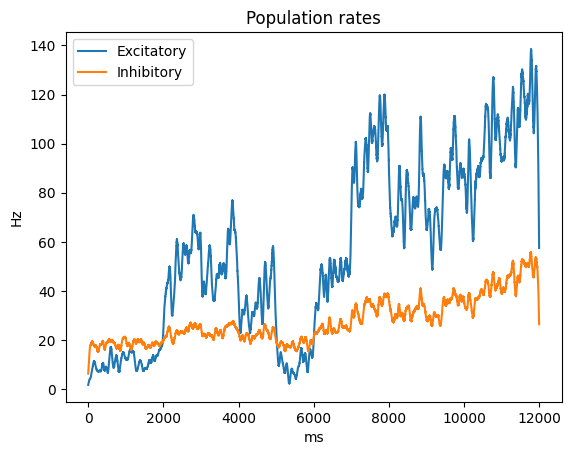

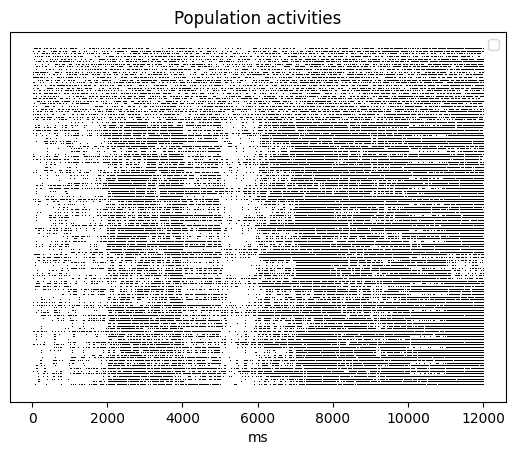

WARNING    /tmp/ipykernel_11486/2515966738.py:37: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
 [py.warnings]
  plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)

WARNING    /tmp/ipykernel_11486/2515966738.py:38: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string ",k" (-> color='k'). The keyword argument will take precedence.
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
 [py.warnings]
  plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)



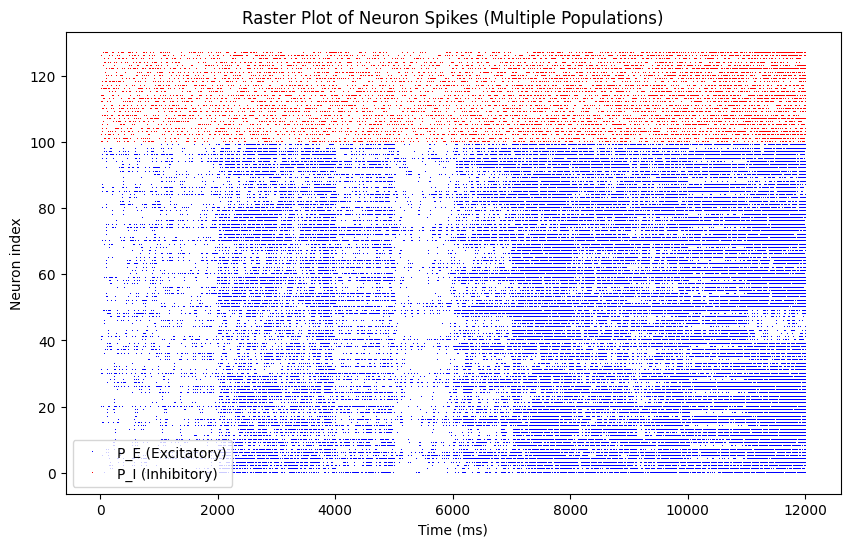

In [7]:
# plotting
title('Population rates')
xlabel('ms')
ylabel('Hz')
plot(r_E.t / ms, r_E.smooth_rate(width=25 * ms) / Hz, label='Excitatory')
plot(r_I.t / ms, r_I.smooth_rate(width=25 * ms) / Hz, label='Inhibitory')
legend()
show()
spike_times = np.concatenate([sp_E.t, sp_I.t])
spike_indices = np.concatenate([sp_E.i, sp_I.i + N_E])

title("Population activities")
xlabel('ms')
yticks([])
plot(spike_times/ms, spike_indices, ',k')
legend()
show()



# def plot_mean_weight(state_mon, label):
#     mean_weight = np.mean(state_mon.w, axis=0)
#     plt.plot(state_mon.t/second, mean_weight, label=label)

# plt.figure()
# plot_mean_weight(mon_C_E_E, 'E→E')
# plot_mean_weight(mon_C_E_I, 'E→I')
# plot_mean_weight(mon_C_I_E, 'I→E')
# plot_mean_weight(mon_C_I_I, 'I→I')
# plt.xlabel('Time (s)')
# plt.ylabel('Mean synaptic weight')
# plt.title('Average synaptic weight over time')
# plt.legend()
# plt.show()

plt.figure(figsize=(10, 6))
plt.plot(sp_E.t / ms, sp_E.i, ',k', label='P_E (Excitatory)', color='blue', markersize=2)
plt.plot(sp_I.t / ms, sp_I.i + N_E, ',k', label='P_I (Inhibitory)', color='red', markersize=2)
plt.xlabel('Time (ms)')
plt.ylabel('Neuron index')
plt.title('Raster Plot of Neuron Spikes (Multiple Populations)')
plt.legend()
plt.show()

In [7]:
print(net['inp'].rates[:])
# net['inp'].rates = rate_seq[1]/Hz
# print(net['inp'].rates)



[33.33333333 33.33333333  0.         16.66666667 16.66666667  0.
 50.          0.         16.66666667 16.66666667 16.66666667 16.66666667
 33.33333333 33.33333333  0.         16.66666667 16.66666667  0.
 50.          0.         16.66666667 16.66666667 16.66666667 16.66666667
 33.33333333 33.33333333  0.         16.66666667 16.66666667  0.
 50.          0.         16.66666667 16.66666667 16.66666667 16.66666667
 33.33333333 33.33333333  0.         16.66666667 16.66666667  0.
 50.          0.         16.66666667 16.66666667 16.66666667 16.66666667
 33.33333333 33.33333333  0.         16.66666667 16.66666667  0.
 50.          0.         16.66666667 16.66666667 16.66666667 16.66666667
 33.33333333 33.33333333  0.         16.66666667 16.66666667  0.
 50.          0.         16.66666667 16.66666667 16.66666667 16.66666667
 33.33333333 33.33333333  0.         16.66666667 16.66666667  0.
 50.          0.         16.66666667 16.66666667 16.66666667 16.66666667
 33.33333333 33.33333333  0.      

In [5]:
print(C_PG_E.i[:])

[  0  12  24   1  13  25   2  14  26   1  13  25   2  14  26   3  15  27
   2  14  26   3  15  27   4  16  28   3  15  27   4  16  28   5  17  29
   4  16  28   5  17  29   6  18  30   5  17  29   6  18  30   7  19  31
   6  18  30   7  19  31   8  20  32   7  19  31   8  20  32   9  21  33
   8  20  32   9  21  33  10  22  34   9  21  33  10  22  34  11  23  35
  12  24  36  13  25  37  14  26  38  13  25  37  14  26  38  15  27  39
  14  26  38  15  27  39  16  28  40  15  27  39  16  28  40  17  29  41
  16  28  40  17  29  41  18  30  42  17  29  41  18  30  42  19  31  43
  18  30  42  19  31  43  20  32  44  19  31  43  20  32  44  21  33  45
  20  32  44  21  33  45  22  34  46  21  33  45  22  34  46  23  35  47
  24  36  48  25  37  49  26  38  50  25  37  49  26  38  50  27  39  51
  26  38  50  27  39  51  28  40  52  27  39  51  28  40  52  29  41  53
  28  40  52  29  41  53  30  42  54  29  41  53  30  42  54  31  43  55
  30  42  54  31  43  55  32  44  56  31  43  55  3

In [22]:
conn_data = C_PG_E.get_states(['i', 'j', 'w'])
print(len(conn_data['i']))
# for i, j, w_ij in zip(conn_data['i'], conn_data['j'], conn_data['w']):
#     print(i,j,w_ij)
print(conn_data['j'])


900
[ 0  0  0  0  0  0  0  0  0  1  1  1  1  1  1  1  1  1  2  2  2  2  2  2
  2  2  2  3  3  3  3  3  3  3  3  3  4  4  4  4  4  4  4  4  4  5  5  5
  5  5  5  5  5  5  6  6  6  6  6  6  6  6  6  7  7  7  7  7  7  7  7  7
  8  8  8  8  8  8  8  8  8  9  9  9  9  9  9  9  9  9 10 10 10 10 10 10
 10 10 10 11 11 11 11 11 11 11 11 11 12 12 12 12 12 12 12 12 12 13 13 13
 13 13 13 13 13 13 14 14 14 14 14 14 14 14 14 15 15 15 15 15 15 15 15 15
 16 16 16 16 16 16 16 16 16 17 17 17 17 17 17 17 17 17 18 18 18 18 18 18
 18 18 18 19 19 19 19 19 19 19 19 19 20 20 20 20 20 20 20 20 20 21 21 21
 21 21 21 21 21 21 22 22 22 22 22 22 22 22 22 23 23 23 23 23 23 23 23 23
 24 24 24 24 24 24 24 24 24 25 25 25 25 25 25 25 25 25 26 26 26 26 26 26
 26 26 26 27 27 27 27 27 27 27 27 27 28 28 28 28 28 28 28 28 28 29 29 29
 29 29 29 29 29 29 30 30 30 30 30 30 30 30 30 31 31 31 31 31 31 31 31 31
 32 32 32 32 32 32 32 32 32 33 33 33 33 33 33 33 33 33 34 34 34 34 34 34
 34 34 34 35 35 35 35 35 35 35 35 35 36 36 36 3